In [1]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 

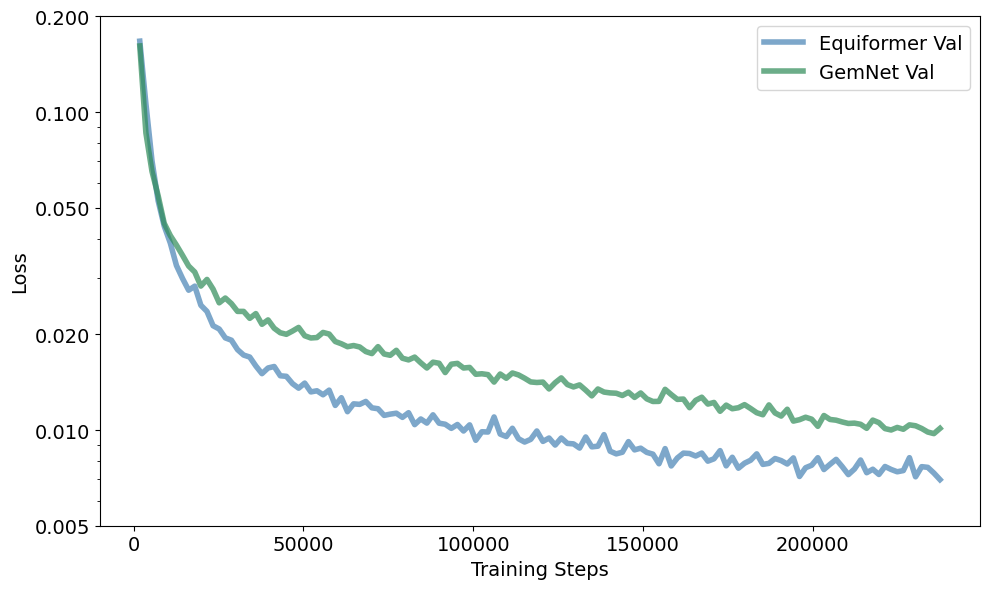

In [2]:
# Read the loss data
df = pd.read_csv('gemnet_equv2_loss.csv')

# Extract columns
steps = df['trainer/global_step']
equiformer_train_loss = df['equiformer-base - train/loss_epoch']
equiformer_val_loss = df['equiformer-base - val/loss']
gemnet_train_loss = df['gemnet-oc - train/loss_epoch']
gemnet_val_loss = df['gemnet-oc - val/loss']

# Find last valid index for equiformer data
last_valid_idx = equiformer_train_loss.last_valid_index()

# Plot training and validation loss curves
fig, ax = plt.subplots(figsize=(10, 6))

# Validation losses (dashed lines)
ax.plot(steps[:last_valid_idx+1], equiformer_val_loss[:last_valid_idx+1], label='Equiformer Val', color='steelblue', linewidth=4, alpha=0.7)
ax.plot(steps[:last_valid_idx+1], gemnet_val_loss[:last_valid_idx+1], label='GemNet Val', color='seagreen', linewidth=4, alpha=0.7)

ax.set_yscale('log')
ax.set_yticks([0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
ax.set_xlabel('Training Steps', fontsize=14)
ax.set_ylabel('Loss', fontsize=14)
ax.legend(fontsize=14)
ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()

plt.savefig('plots/gemnet_equv2_loss.pdf', dpi=300, bbox_inches='tight')

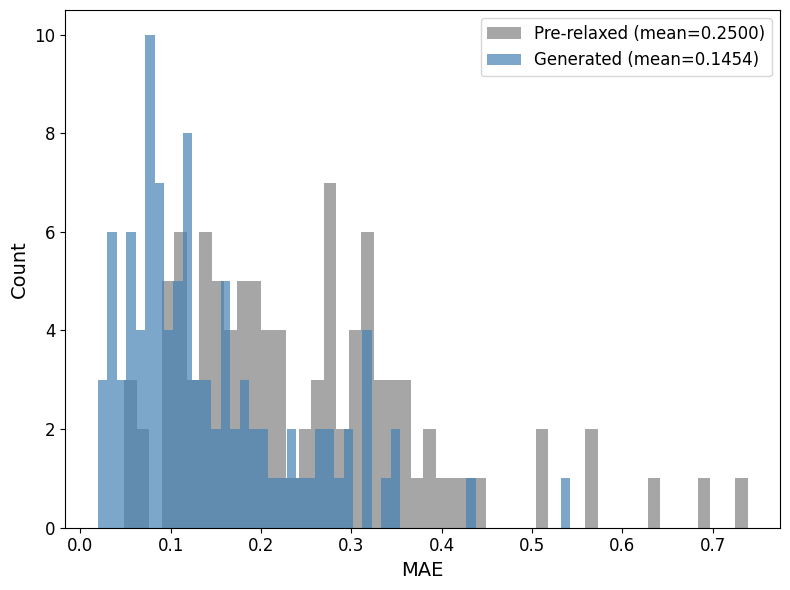

In [3]:
# Load test set metrics
initial_mae = np.load('train-metrics/initial_mae.npy')
generated_mae = np.load('train-metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(initial_mae, bins=50, alpha=0.7, label=f'Pre-relaxed (mean={initial_mae.mean():.4f})', color='grey')
ax.hist(generated_mae, bins=50, alpha=0.7, label=f'Generated (mean={generated_mae.mean():.4f})', color='steelblue')
ax.set_xlabel('MAE', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/train_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

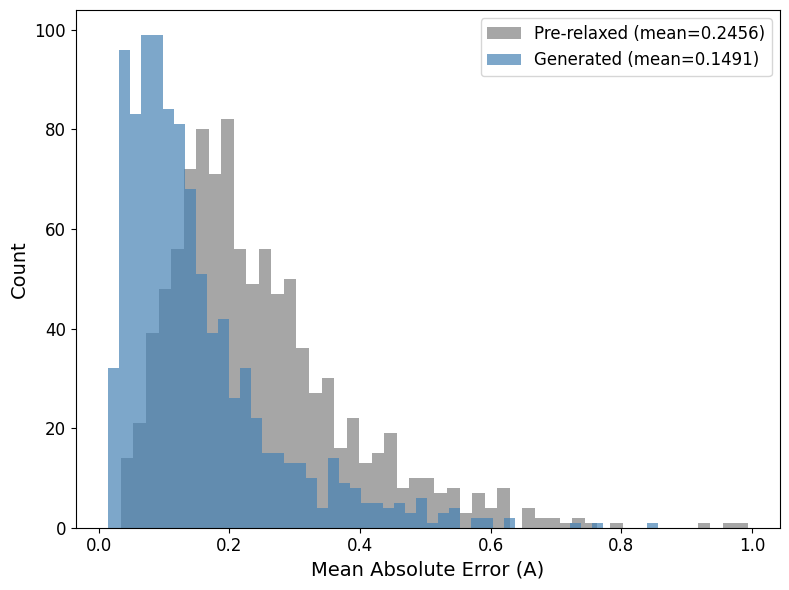

In [4]:
# Load test set metrics
initial_mae = np.load('val_id-metrics/initial_mae.npy')
generated_mae = np.load('val_id-metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(initial_mae, bins=50, alpha=0.7, label=f'Pre-relaxed (mean={initial_mae.mean():.4f})', color='grey')
ax.hist(generated_mae, bins=50, alpha=0.7, label=f'Generated (mean={generated_mae.mean():.4f})', color='steelblue')
ax.set_xlabel('Mean Absolute Error (A)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_id_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

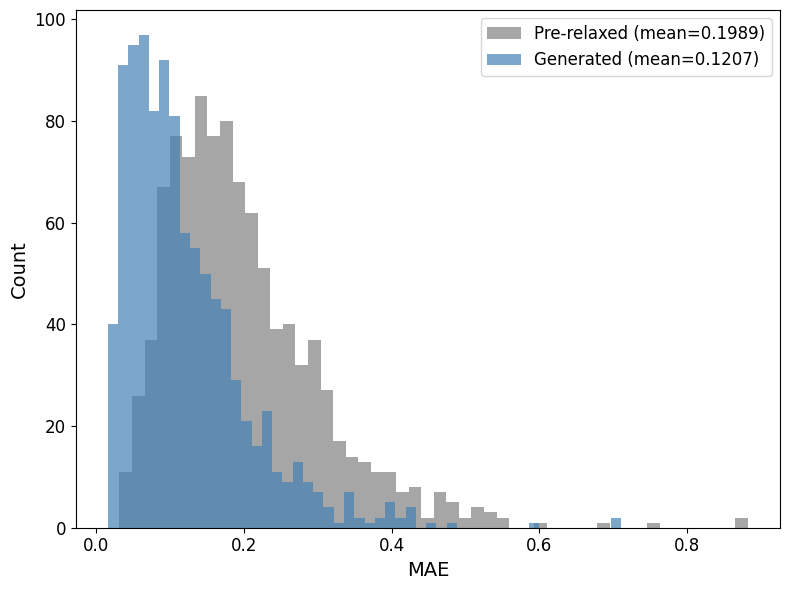

In [5]:
# Load test set metrics
initial_mae = np.load('val_ood_both-metrics/initial_mae.npy')
generated_mae = np.load('val_ood_both-metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(initial_mae, bins=50, alpha=0.7, label=f'Pre-relaxed (mean={initial_mae.mean():.4f})', color='grey')
ax.hist(generated_mae, bins=50, alpha=0.7, label=f'Generated (mean={generated_mae.mean():.4f})', color='steelblue')
ax.set_xlabel('MAE', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

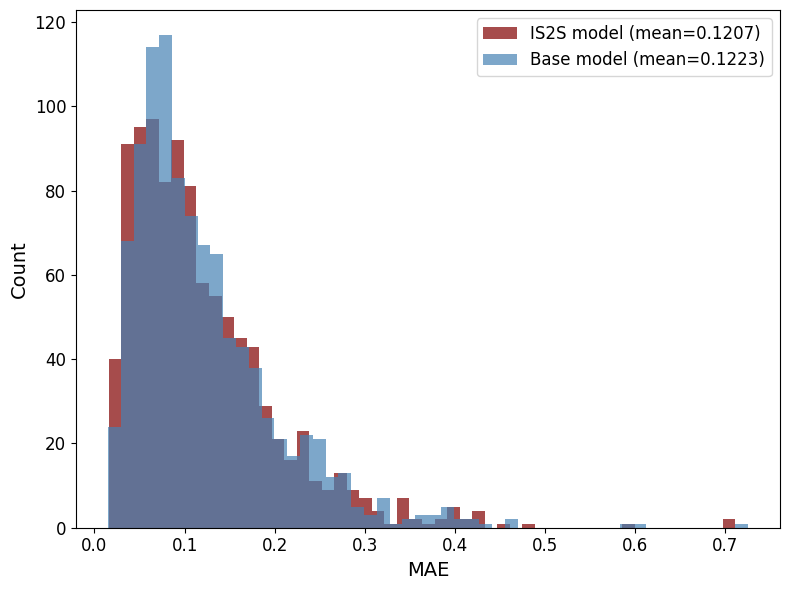

In [10]:
# Load test set metrics
is2s_mae = np.load('val_ood_both-metrics/generated_mae.npy')
base_mae = np.load('is2s_val_ood_both-metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(initial_mae, bins=50, alpha=0.7, label=f'IS2S model (mean={initial_mae.mean():.4f})', color='maroon')
ax.hist(generated_mae, bins=50, alpha=0.7, label=f'Base model (mean={generated_mae.mean():.4f})', color='steelblue')
ax.set_xlabel('MAE', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

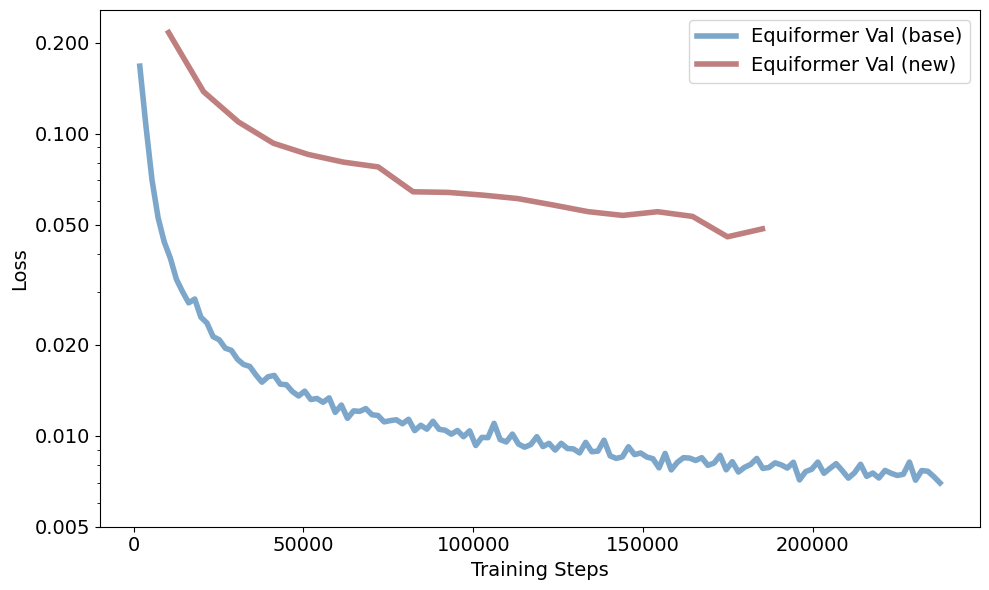

In [6]:
# Read the loss data
df1 = pd.read_csv('gemnet_equv2_loss.csv')
df2 = pd.read_csv('equv2_is2s_flow.csv')

# Extract columns
steps1 = df1['trainer/global_step']
equiformer_val_loss_1 = df1['equiformer-base - val/loss']

steps2 = df2['trainer/global_step']
equiformer_val_loss_2 = df2['equiformer-is2s-flow - val/loss']


# Plot training and validation loss curves
fig, ax = plt.subplots(figsize=(10, 6))

# Validation losses (dashed lines)
ax.plot(steps1, equiformer_val_loss_1, label='Equiformer Val (base)', color='steelblue', linewidth=4, alpha=0.7)
ax.plot(steps2, equiformer_val_loss_2, label='Equiformer Val (new)', color='maroon', linewidth=4, alpha=0.50)

ax.set_yscale('log')
ax.set_yticks([0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
ax.set_xlabel('Training Steps', fontsize=14)
ax.set_ylabel('Loss', fontsize=14)
ax.legend(fontsize=14)
ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()

plt.savefig('plots/equv2_base_vs_new_loss.pdf', dpi=300, bbox_inches='tight')

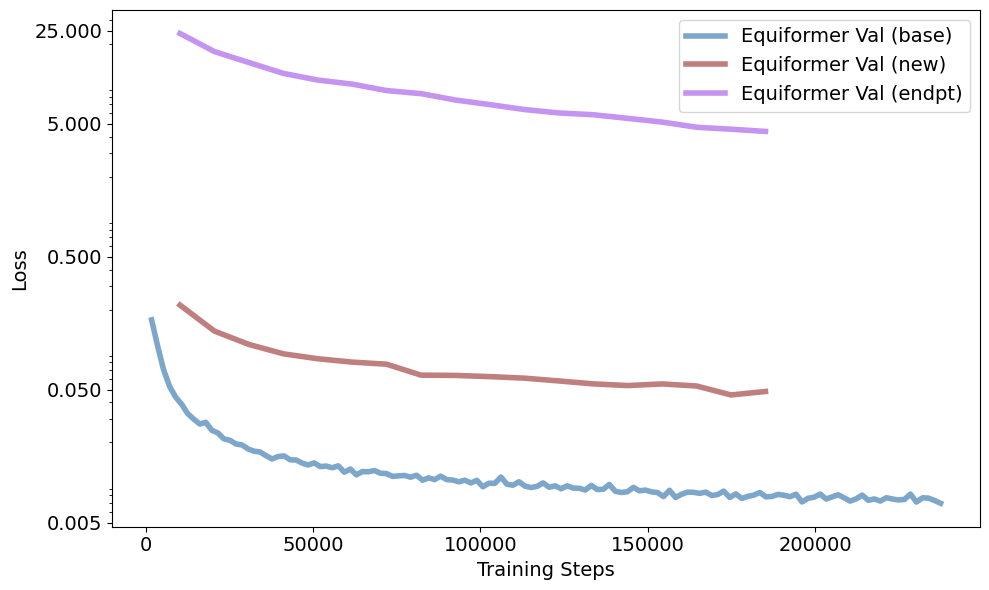

In [7]:
# Read the loss data
df1 = pd.read_csv('gemnet_equv2_loss.csv')
df2 = pd.read_csv('equv2_is2s_flow.csv')
df3 = pd.read_csv('equv2_is2s_endpt.csv')

# Extract columns
steps1 = df1['trainer/global_step']
equiformer_val_loss_1 = df1['equiformer-base - val/loss']

steps2 = df2['trainer/global_step']
equiformer_val_loss_2 = df2['equiformer-is2s-flow - val/loss']

steps3 = df3['trainer/global_step']
equiformer_val_loss_3 = df3['equiformer-is2s-endpt - val/loss']


# Plot training and validation loss curves
fig, ax = plt.subplots(figsize=(10, 6))

# Validation losses (dashed lines)
ax.plot(steps1, equiformer_val_loss_1, label='Equiformer Val (base)', color='steelblue', linewidth=4, alpha=0.7)
ax.plot(steps2, equiformer_val_loss_2, label='Equiformer Val (new)', color='maroon', linewidth=4, alpha=0.50)
ax.plot(steps3, equiformer_val_loss_3, label='Equiformer Val (endpt)', color='blueviolet', linewidth=4, alpha=0.50)

ax.set_yscale('log')
ax.set_yticks([0.005, 0.05, 0.5, 5, 25])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
ax.set_xlabel('Training Steps', fontsize=14)
ax.set_ylabel('Loss', fontsize=14)
ax.legend(fontsize=14)
ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()

plt.savefig('plots/equv2_base_vs_new_vs_endpt_loss.pdf', dpi=300, bbox_inches='tight')